In [13]:
import numpy as np
import pandas as pd

import sxs
path_to_codes = '/home/samanwaya/gwfit/gwfit/'
import sys
sys.path.append(path_to_codes)
import useful_relations as urel
import constants as const
import nr_data_utils as nr

import h5py as h5
import json
import matplotlib.pyplot as plt
plt.rcParams.update({
                    "mathtext.fontset": "cm",
                    })

plt.rcParams.update({
    "font.size": 14,          # Default font size
    "axes.labelsize": 14,     # x/y labels
    "axes.titlesize": 18,     # Axes title
    "xtick.labelsize": 11,    # Tick labels
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.titlesize": 20,
})
# plt.rcParams["font.size"] = 14

In [38]:
sxs.sxs_directory("config")
sxs.write_config(download=True, cache=True, auto_supersede=True)
sxs.read_config()
sxs.sxs_directory("cache")

PosixPath('/home/samanwaya/.cache/sxs')

In [39]:
simulations = sxs.load("simulations")

df = simulations.dataframe

# Nonspinning BBHs
df_filtered = nr.filter_simulations(
    df,
    q=(1,None),
    chi1=(0, 1e-4),
    chi2=(0, 1e-4),
)

In [40]:
# df_filtered_short = df_filtered[[
#             "reference_time",
#             "reference_mass_ratio",
#             "reference_dimensionless_spin1",
#             "reference_dimensionless_spin2",
#             "number_of_orbits",
#             "reference_eccentricity"
#           ]]  # specify which entries you want to show on the dataframe

df_filtered_sorted = df_filtered.sort_values("reference_mass_ratio") #sorted by increasing mass ratio

nonspinning_circular_labels = df_filtered_sorted.index.to_numpy(dtype=str)
print(len(nonspinning_circular_labels))
print(nonspinning_circular_labels)

32
['SXS:BBH:1132' 'SXS:BBH:1154' 'SXS:BBH:1155' 'SXS:BBH:1153'
 'SXS:BBH:3617' 'SXS:BBH:2375' 'SXS:BBH:2376' 'SXS:BBH:2325'
 'SXS:BBH:2326' 'SXS:BBH:2331' 'SXS:BBH:3984' 'SXS:BBH:1166'
 'SXS:BBH:1167' 'SXS:BBH:2265' 'SXS:BBH:2483' 'SXS:BBH:2484'
 'SXS:BBH:3144' 'SXS:BBH:2487' 'SXS:BBH:3619' 'SXS:BBH:2486'
 'SXS:BBH:2489' 'SXS:BBH:2488' 'SXS:BBH:2491' 'SXS:BBH:2490'
 'SXS:BBH:2493' 'SXS:BBH:2707' 'SXS:BBH:2492' 'SXS:BBH:2495'
 'SXS:BBH:1108' 'SXS:BBH:2494' 'SXS:BBH:2480' 'SXS:BBH:2477']


In [41]:
freq_data = {}
dMdt_data = {}
gw_flux_data = {}
q_values = {}
for sim_label in nonspinning_circular_labels:
# for sim_label in ['SXS:BBH:2480']:
    sim_prem = nr.SXSSimulation(simulation_label=sim_label,
                                    initial_cutoff='reference',
                                    final_cutoff='common_horizon',
                               )
    print(sim_label,sim_prem.metadata.reference_mass_ratio)
    
    twf, gw_freq = sim_prem.mode_frequency(mode=(2,2))
    _, gw_flux = sim_prem.gw_flux(ell_max=8)
    orb_freq = gw_freq/2.
    # plt.plot(twf,gw_freq)
    t, fA, fB = sim_prem.horizon.component_horizon_fluxes(times_to_interpolate=twf)

    dMdt = fA + fB

    mask = (
        (twf >= t[0]) &
        (twf <= t[-1])
    )

    gw_freq = gw_freq[mask]
    gw_flux = gw_flux[mask]

    freq_data[sim_label] = gw_freq
    dMdt_data[sim_label] = dMdt
    gw_flux_data[sim_label] = gw_flux

    q_values[sim_label] = sim_prem.metadata.reference_mass_ratio
    
#     plt.semilogy(gw_freq,dMdt,c='green')
#     plt.semilogy(gw_freq,gw_flux,c='k', alpha=0.5)
# plt.xlim(0.028,0.044)
# plt.ylim(1e-7,2e-3)
# plt.grid()
# plt.show()

SXS:BBH:1132 1.0000000000777731
SXS:BBH:1154 1.0000000088810654
SXS:BBH:1155 1.0000000167839966
SXS:BBH:1153 1.0000000339507276
SXS:BBH:3617 1.0000000921882035
SXS:BBH:2375 1.0000001464378543
SXS:BBH:2376 1.00000015893398
SXS:BBH:2325 1.0000001655510153
SXS:BBH:2326 1.0000002355349868
SXS:BBH:2331 1.4999898222503383
SXS:BBH:3984 1.4999984786560454
SXS:BBH:1166 2.000020628268884
SXS:BBH:1167 2.0001080187362943
SXS:BBH:2265 3.000112224984311
SXS:BBH:2483 3.499942504651751
SXS:BBH:2484 4.4995631767635835
SXS:BBH:3144 4.499621846563142
SXS:BBH:2487 4.999936029137081
SXS:BBH:3619 5.000307275688211
SXS:BBH:2486 5.50003563689487
SXS:BBH:2489 5.999531974378745
SXS:BBH:2488 6.499550871499383
SXS:BBH:2491 7.00017202109518
SXS:BBH:2490 7.49959753009933
SXS:BBH:2493 7.999879065402133
SXS:BBH:2707 8.000149200385618
SXS:BBH:2492 8.50110106507095
SXS:BBH:2495 9.000894345205925
SXS:BBH:1108 9.199933130774635
SXS:BBH:2494 9.49734337785268
SXS:BBH:2480 14.000176436745123
SXS:BBH:2477 14.999984440092447


No crossing for SXS:BBH:1132, q = 1.0000000000777731
No crossing for SXS:BBH:1154, q = 1.0000000088810654
No crossing for SXS:BBH:1155, q = 1.0000000167839966
No crossing for SXS:BBH:1153, q = 1.0000000339507276
No crossing for SXS:BBH:3617, q = 1.0000000921882035
No crossing for SXS:BBH:2375, q = 1.0000001464378543
No crossing for SXS:BBH:2376, q = 1.00000015893398
No crossing for SXS:BBH:2325, q = 1.0000001655510153
No crossing for SXS:BBH:2326, q = 1.0000002355349868
No crossing for SXS:BBH:2331, q = 1.4999898222503383
No crossing for SXS:BBH:3984, q = 1.4999984786560454
No crossing for SXS:BBH:1166, q = 2.000020628268884
No crossing for SXS:BBH:1167, q = 2.0001080187362943


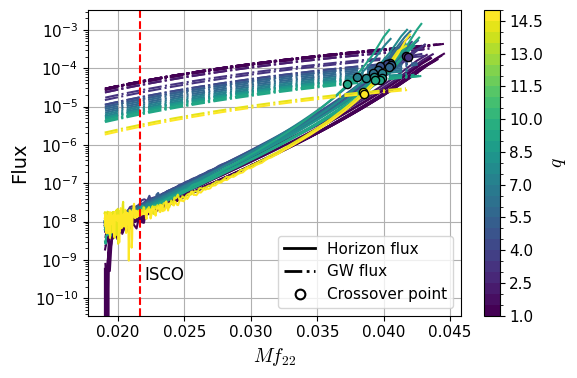

In [76]:
from matplotlib import colormaps, cm
from matplotlib.colors import Normalize, BoundaryNorm


# Colormap and normalization
cmap = colormaps["viridis"]      

# Bin edges every 0.5 in q
bounds = np.arange(1, 15.5, 0.5)   # 3.0, 3.5, ..., 15.0
norm = BoundaryNorm(bounds, cmap.N)

flux_ratio = {}

isco = 1./(6*np.sqrt(6)*np.pi)
Mf_star = {}
MOmegaOrb_star = {}
fig, ax = plt.subplots(figsize=(6, 4))

for i, sim_label in enumerate(nonspinning_circular_labels):
    q = q_values[sim_label]
    # if q<3:
    #     continue
    dMdt = dMdt_data[sim_label]
    gw_freq = freq_data[sim_label]
    gw_flux = gw_flux_data[sim_label]

    flux_ratio[sim_label] = dMdt / gw_flux
    
    
    color = cmap(norm(q))
    
    idxstart = np.searchsorted(gw_freq,0.019)
    dMdt = dMdt[idxstart:]
    gw_freq = gw_freq[idxstart:]
    gw_flux = gw_flux[idxstart:]
    # omega_orb = 
    
    diff = dMdt - gw_flux
    # Indices where the sign changes
    idx = np.where(np.diff(np.sign(diff)) != 0)[0]

    if len(idx):
        i1 = idx[0]

        # Linear interpolation
        t_cross = np.interp(0, diff[i1:i1+2], gw_freq[i1:i1+2])
        y_cross = np.interp(t_cross, gw_freq[i1:i1+2], dMdt[i1:i1+2])

        Mf_star[sim_label] = t_cross
        MOmegaOrb_star[sim_label] = t_cross * np.pi
    
        ax.scatter(t_cross, y_cross,
                   color=color,
                   edgecolor='k',
                   s=35,
                   zorder=10
               )
    else:
        print(f'No crossing for {sim_label}, q = {q_values[sim_label]}')
    
    ax.semilogy(gw_freq, dMdt, color=color)
    ax.semilogy(gw_freq, gw_flux, color=color,ls='-.')

# Create colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
plt.axvline(isco,c='r',ls='--')
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("$q$")
plt.xlabel('$Mf_{22}$')
plt.ylabel('Flux')
# plt.xlim(right=0.044)
# plt.ylim(3e-8,2e-3)
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0], [0],
           color='black',
           lw=2,
           linestyle='-',
           label='Horizon flux'),

    Line2D([0], [0],
           color='black',
           lw=2,
           linestyle='-.',
           label='GW flux'),

    Line2D([0], [0],
           marker='o',
           linestyle='None',
           markerfacecolor='white',
           markeredgecolor='black',
           markeredgewidth=1.5,
           markersize=7,
           label='Crossover point'),

]

ax.legend(handles=legend_handles, loc='best', frameon=True)
plt.tight_layout()
plt.grid()
plt.text(0.022,3e-10,'ISCO',fontsize=12)
plt.savefig('/home/samanwaya/HFluxNR/data_and_plots/flux_comparison.png',dpi=200)
plt.show()

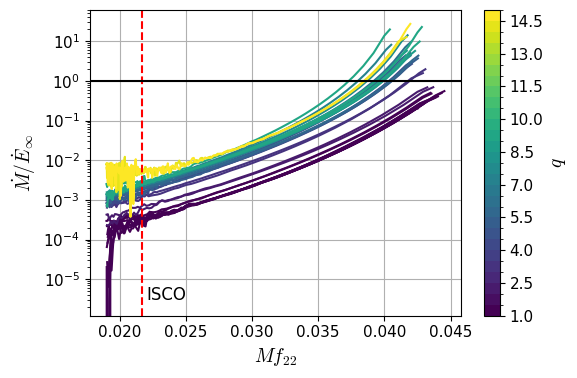

In [77]:
fig, ax = plt.subplots(figsize=(6, 4))

for sim_label in nonspinning_circular_labels:
    dMdt = dMdt_data[sim_label]
    gw_freq = freq_data[sim_label]
    gw_flux = gw_flux_data[sim_label]

    flux_ratio = dMdt / gw_flux
    
    q = q_values[sim_label]
    color = cmap(norm(q))
    
    idxstart = np.searchsorted(gw_freq,0.019)
    dMdt = dMdt[idxstart:]
    gw_freq = gw_freq[idxstart:]
    gw_flux = gw_flux[idxstart:]
    flux_ratio = flux_ratio[idxstart:]
    MOmega_orb = gw_freq *np.pi

    ax.semilogy(gw_freq,flux_ratio,color=color)
    # ax.semilogy(MOmega_orb,flux_ratio,color=color)
plt.axvline(isco ,c='r',ls='--')#,label='ISCO')
# plt.axvline(isco * np.pi,c='r',ls='--',label='ISCO')
plt.axhline(1,c='k',)
plt.xlabel('$Mf_{22}$')
# plt.xlabel('$M\\omega_{\\rm orb}$')
plt.ylabel('$\\dot{M}/\\dot{E}_\\infty$')
plt.grid()
# plt.legend()
plt.text(0.022,3e-6,'ISCO',fontsize=12)

# plt.yticks(ticks,labels)
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("$q$")
plt.tight_layout()
plt.savefig('/home/samanwaya/HFluxNR/data_and_plots/flux_ratio',dpi=200)
# plt.savefig('/home/samanwaya/HFluxNR/data_and_plots/flux_ratio_with_omega_orb',dpi=200)
plt.show()

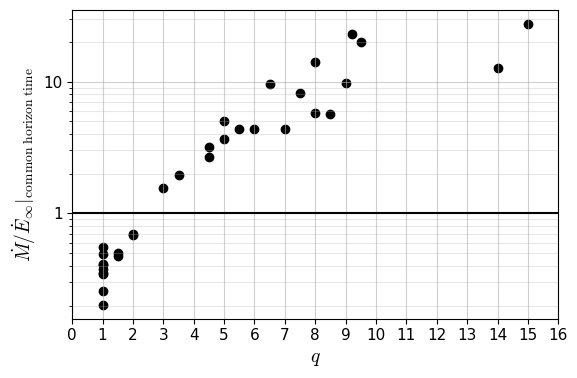

In [83]:
fig, ax = plt.subplots(figsize=(6, 4))

for sim_label in nonspinning_circular_labels:
    dMdt = dMdt_data[sim_label]
    gw_freq = freq_data[sim_label]
    gw_flux = gw_flux_data[sim_label]

    flux_ratio = dMdt / gw_flux
    R_final = flux_ratio[-1]
     
    q = q_values[sim_label]
    

    ax.scatter(q,R_final,color='k')
    # ax.semilogy(MOmega_orb,flux_ratio,color=color)
# plt.axvline(isco ,c='r',ls='--',label='ISCO')
# plt.axvline(isco * np.pi,c='r',ls='--',label='ISCO')
plt.yscale('log')
plt.axhline(1,c='k',)
# plt.axvline(3)
plt.xlabel('$q$')
# plt.xlabel('$M\\omega_{\\rm orb}$')
plt.ylabel('$\\dot{M}/\\dot{E}_\\infty|_{\\rm common ~horizon ~time}$')
# plt.grid()
# plt.legend()
# ticks = [1e-3, 1e-2, 1e-1, 1, 10, 100]
# labels = [
#     r"$10^{-3}$",
#     r"$10^{-2}$",
#     r"$10^{-1}$",
#     r"$1$",
#     r"$10$",
#     r"$100$",
# ]

# ticks = ax.get_xticks()
# ticks = np.sort(np.append(ticks, 3))
ticks = np.linspace(0,16,17)
ax.set_xticks(ticks)
ax.set_yticks([1,10],[1,10])
from matplotlib.ticker import LogLocator

# Major ticks at powers of 10
ax.yaxis.set_major_locator(LogLocator(base=10))

# Minor ticks at 2,3,...,9 within each decade
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))

# Grid
ax.grid(which='major', alpha=0.6)
ax.grid(which='minor', alpha=0.3)
# plt.yticks(ticks,labels)
# sm = cm.ScalarMappable(norm=norm, cmap=cmap)
# cbar = plt.colorbar(sm, ax=ax)
# cbar.set_label("$q$")
plt.tight_layout()
plt.savefig('/home/samanwaya/HFluxNR/data_and_plots/flux_ratio_com_hor',dpi=200)
plt.show()

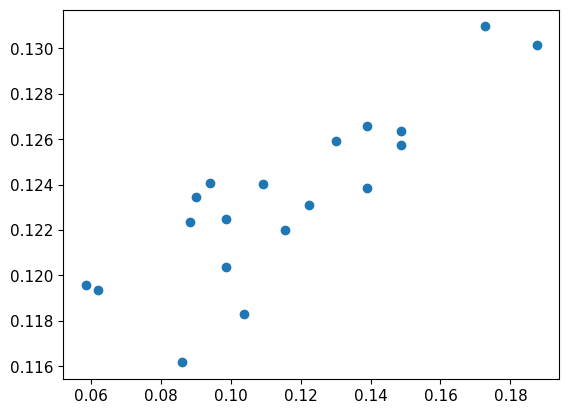

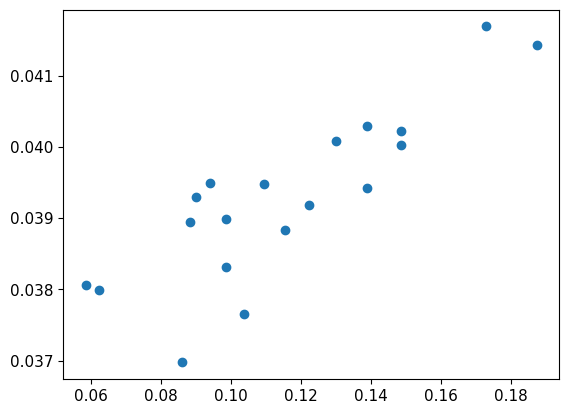

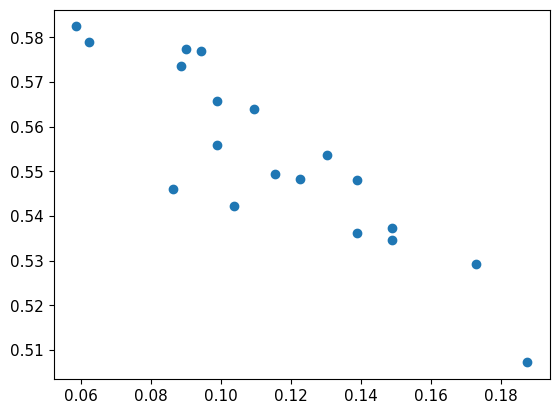

In [107]:
Mf_star_vals = np.array(list(Mf_star.values())) 
q_vals = np.array(list(q_values.values()))
eta_vals = q_vals/(1+q_vals)**2
Mf_LR = ((1+q_vals)/q_vals)*(1/(3*np.sqrt(3)*np.pi))
Mf_star_scaled = Mf_star_vals / Mf_LR
MOmegaOrb_star_vals = np.array(list(MOmegaOrb_star.values()))

plt.scatter(eta_vals,MOmegaOrb_star_vals)
plt.show()

plt.scatter(eta_vals,Mf_star_vals)
plt.show()

plt.scatter(eta_vals,Mf_star_scaled)
plt.show()